hw9
==========

In [1]:

import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import time
import random
import pandas as pd
import numpy as np
import keras
import keras_hub as kh
import evaluate
from datasets import load_dataset, Dataset, Features, Value, ClassLabel
from sklearn.model_selection import train_test_split


from IPython.display import display, Markdown, HTML
from sklearn.metrics import ConfusionMatrixDisplay

from keras import mixed_precision                    # generally faster
mixed_precision.set_global_policy("mixed_float16")

I0000 00:00:1793459492.943335    1162 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
def format_hms(seconds):
    """Format elapsed seconds as H:MM:SS."""
    return time.strftime("%H:%M:%S", time.gmtime(seconds))

-------
# 0 - config

In [3]:

# ------------ Global Configuration ------------

SEED = 42

# Model and training settings
MAX_LEN = 128
EPOCHS = 2
BATCH = 32
EVAL_BATCH = 64




In [4]:
# Development workflow
# Use "smoke" for debugging, "dev" for development,
# "baseline" for 25%, or "full" for 100%.

DATA_MODE = "baseline"

DATA_FRACTIONS = {
    "smoke":    0.01,   # 1% of training pool
    "dev":      0.10,   # 10% of training pool
    "baseline": 0.25,   # 25% of training pool
    "full":     1.00    # Entire training pool
}



In [5]:
assert DATA_MODE in DATA_FRACTIONS
TRAIN_FRAC = DATA_FRACTIONS[DATA_MODE]


keras.utils.set_random_seed(SEED)

print(f"Data mode: {DATA_MODE}")
print(f"Training fraction: {TRAIN_FRAC:.0%}")


Data mode: baseline
Training fraction: 25%


In [6]:

# ------------ Load and Partition IMDB ------------

imdb = load_dataset("stanfordnlp/imdb")

# Preserve the original held-out test set
test_ds = imdb["test"]

# Create a fixed, stratified validation set
indices = np.arange(len(imdb["train"]))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.10,
    random_state=SEED,
    stratify=np.array(imdb["train"]["label"])
)

train_pool = imdb["train"].select(train_idx.tolist())
val_ds = imdb["train"].select(val_idx.tolist())

# ------------ Reproducible Nested Training Subsets ------------

# Shuffle each class independently, then interleave classes.
# This gives balanced, nested training subsets.
rng = np.random.default_rng(SEED)

labels = np.array(train_pool["label"])
neg_idx = np.flatnonzero(labels == 0)
pos_idx = np.flatnonzero(labels == 1)

rng.shuffle(neg_idx)
rng.shuffle(pos_idx)

train_order = np.column_stack((neg_idx, pos_idx)).ravel()

def get_training_subset(frac):
    """Return a balanced, nested fraction of the training pool."""
    if not 0 < frac <= 1:
        raise ValueError("frac must be in (0, 1].")

    n_pairs = max(1, round(len(train_order) * frac / 2))
    selected = train_order[:2 * n_pairs]

    return train_pool.select(selected.tolist())

# Apply the development throttle
train_ds = get_training_subset(TRAIN_FRAC)

# ------------ NumPy Arrays for Keras ------------

X_tr = np.array(train_ds["text"], dtype=object)
y_tr = np.array(train_ds["label"], dtype="int32")

X_va = np.array(val_ds["text"], dtype=object)
y_va = np.array(val_ds["label"], dtype="int32")

X_te = np.array(test_ds["text"], dtype=object)
y_te = np.array(test_ds["label"], dtype="int32")

# ------------ Summary ------------

def _counts(ds):
    values = np.array(ds["label"], dtype=int)
    return len(values), np.bincount(values, minlength=2).tolist()

print(f"Data mode: {DATA_MODE} ({TRAIN_FRAC:.0%})")
print("Training pool:", _counts(train_pool))
print("Training subset:", _counts(train_ds))
print("Validation:", _counts(val_ds))
print("Test:", _counts(test_ds))

# ---- DistilBERT baseline: develop using the selected data throttle ----

print(f"Data mode: {DATA_MODE}")
print(f"Training examples: {len(X_tr):,}")
print(f"Validation examples: {len(X_va):,}")
print(f"Maximum sequence length: {MAX_LEN}")
print(f"Batch size: {BATCH}")

# Build preprocessor and classifier
keras.utils.set_random_seed(SEED)

preproc = kh.models.DistilBertTextClassifierPreprocessor.from_preset(
    "distil_bert_base_en_uncased",
    sequence_length=MAX_LEN
)

model = kh.models.DistilBertTextClassifier.from_preset(
    "distil_bert_base_en_uncased",
    num_classes=2,
    preprocessor=preproc
)

model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="acc")]
)

# ---- Train with early stopping ----

cb = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
]

start = time.perf_counter()

history = model.fit(
    X_tr, y_tr,
    validation_data=(X_va, y_va),
    epochs=EPOCHS,
    batch_size=BATCH,
    callbacks=cb,
    verbose=1
)

elapsed = time.perf_counter() - start

# ---- Evaluate the restored model on validation data ----

val_loss, val_acc = model.evaluate(
    X_va, y_va,
    batch_size=EVAL_BATCH,
    verbose=0
)

logits = model.predict(
    X_va,
    batch_size=EVAL_BATCH,
    verbose=0
)

y_pred = np.argmax(logits, axis=-1)

acc_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

acc = acc_metric.compute(
    predictions=y_pred,
    references=y_va
)["accuracy"]

f1 = f1_metric.compute(
    predictions=y_pred,
    references=y_va
)["f1"]

# ---- Confusion matrix ----

def confusion_matrix_np(y_true, y_pred, num_classes=2):
    cm = np.zeros((num_classes, num_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm

# ---- Summary ----

best_epoch = np.argmin(history.history["val_loss"]) + 1

print(f"\nBest epoch: {best_epoch}")
print(f"Validation loss (restored model): {val_loss:.4f}")
print(f"Validation accuracy: {acc:.4f}")
print(f"Validation F1: {f1:.4f}")

print("\nValidation confusion matrix:")
print(confusion_matrix_np(y_va, y_pred))

print("\nTraining time:",
      time.strftime("%H:%M:%S", time.gmtime(elapsed)))


Data mode: baseline (25%)
Training pool: (22500, [11250, 11250])
Training subset: (5624, [2812, 2812])
Validation: (2500, [1250, 1250])
Test: (25000, [12500, 12500])
Data mode: baseline
Training examples: 5,624
Validation examples: 2,500
Maximum sequence length: 128
Batch size: 32


I0000 00:00:1793459511.900081    1162 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6071 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2070 SUPER, pci bus id: 0000:01:00.0, compute capability: 7.5


Epoch 1/2


/home/primary-a/miniconda3/envs/tf/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793459534.945320    3447 service.cc:153] XLA service 0x78009c077770 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793459534.945357    3447 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2070 SUPER, Compute Capability 7.5 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.25.1)
I0000 00:00:1793459535.353737    3447 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793459538.641811    3447 cuda_dnn.cc:461] Loaded cuDNN version 92501
I0000 00:00:1793459540.053813    3447 dot_merger.cc:4

175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - acc: 0.7639 - loss: 0.4956

...

176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step - acc: 0.7644 - loss: 0.4947

I0000 00:00:1793459593.807711    3446 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_31170__.70
I0000 00:00:1793459597.483231    3445 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_31170__.70


176/176 ━━━━━━━━━━━━━━━━━━━━ 83s 244ms/step - acc: 0.7644 - loss: 0.4947 - val_acc: 0.8468 - val_loss: 0.3565
Epoch 2/2
176/176 ━━━━━━━━━━━━━━━━━━━━ 15s 85ms/step - acc: 0.8606 - loss: 0.3283 - val_acc: 0.8444 - val_loss: 0.3635


I0000 00:00:1793459617.558836    3444 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_31170__.70
I0000 00:00:1793459624.469986    3444 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_36695__.39
I0000 00:00:1793459628.505653    3447 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_38243__.63



Best epoch: 1
Validation loss (restored model): 0.3565
Validation accuracy: 0.8468
Validation F1: 0.8471

Validation confusion matrix:
[[1056  194]
 [ 189 1061]]

Training time: 00:01:40


In [7]:
format_hms(elapsed)

'00:01:40'

### compile results


In [8]:

Results = {}

best_idx = int(np.argmin(history.history["val_loss"]))

Results["baseline_distilBert"] = {
    "min_val_loss": float(history.history["val_loss"][best_idx]),
    "val_accuracy": float(history.history["val_acc"][best_idx]),
    "best_epoch": best_idx + 1,
    # "training_seconds": elapsed,
    "max_len": MAX_LEN,
    "learning_rate": 1e-5,
    "batch_size": BATCH,
    "n_train": len(X_tr),
    "processing_time": format_hms(elapsed),
}

Results

{'baseline_distilBert': {'min_val_loss': 0.356480211019516,
  'val_accuracy': 0.8468000292778015,
  'best_epoch': 1,
  'max_len': 128,
  'learning_rate': 1e-05,
  'batch_size': 32,
  'n_train': 5624,
  'processing_time': '00:01:40'}}

### chart 

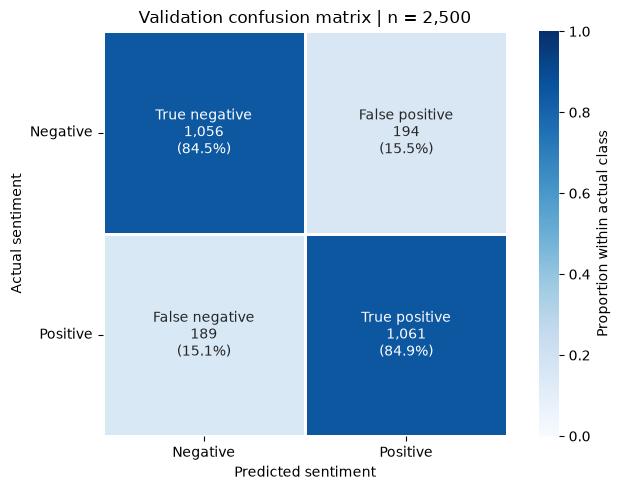

,precision,recall,f1-score,support
Negative,84.8%,84.5%,84.6%,"1,250"
Positive,84.5%,84.9%,84.7%,"1,250"


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report
from IPython.display import display


## __ Calculate counts and percentages within each actual class
class_names = ["Negative", "Positive"]

cm = confusion_matrix(y_va, y_pred, labels=[0, 1])
cm_pct = confusion_matrix(
    y_va, y_pred, labels=[0, 1], normalize="true"
)

## __ Annotate each cell with its meaning, count, and row percentage
cell_names = np.array([
    ["True negative", "False positive"],
    ["False negative", "True positive"],
])

annotations = np.array([
    [
        f"{cell_names[i, j]}\n{cm[i, j]:,}\n({cm_pct[i, j]:.1%})"
        for j in range(2)
    ]
    for i in range(2)
])


## __ Plot validation results
fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    cm_pct,
    annot=annotations,
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=1,
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"label": "Proportion within actual class"},
    ax=ax,
)

ax.set(
    title=f"Validation confusion matrix | n = {cm.sum():,}",
    xlabel="Predicted sentiment",
    ylabel="Actual sentiment",
)
ax.tick_params(axis="both", labelrotation=0)

plt.tight_layout()
plt.show()


## __ Complement the plot with per-class metrics
report_df = (
    pd.DataFrame(
        classification_report(
            y_va,
            y_pred,
            labels=[0, 1],
            target_names=class_names,
            output_dict=True,
            zero_division=0,
        )
    )
    .T
    .loc[class_names, ["precision", "recall", "f1-score", "support"]]
)

display(
    report_df.style.format({
        "precision": "{:.1%}",
        "recall": "{:.1%}",
        "f1-score": "{:.1%}",
        "support": "{:,.0f}",
    })
)

---

# p1

## make function 

In [10]:
def p1_model(
    MAX_LEN, LR, BATCH,
    EPOCHS=2, EVAL_BATCH=64,
    SEED=42,
):
    ## __ Reset model-building state and seed for each experiment
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    ## __ Preprocess
    preprocessor = (
        kh.models.DistilBertTextClassifierPreprocessor
        .from_preset(
            "distil_bert_base_en_uncased",
            sequence_length=MAX_LEN,
        )
    )

    model = (
        kh.models.DistilBertTextClassifier
        .from_preset(
            "distil_bert_base_en_uncased",
            num_classes=2,
            preprocessor=preprocessor,
        )
    )

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LR),
        loss=keras.losses.SparseCategoricalCrossentropy(
            from_logits=True,
        ),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="acc")],
    )

    early_stopping_cb = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
    )

    ## __ Train model
    start = time.perf_counter()

    history = model.fit(
        X_tr,
        y_tr,
        validation_data=(X_va, y_va),
        epochs=EPOCHS,
        batch_size=BATCH,
        callbacks=[early_stopping_cb],
    )

    elapsed = time.perf_counter() - start

    ## __ Predict using the restored best weights
    logits = model.predict(
        X_va,
        batch_size=EVAL_BATCH,
        verbose=0,
    )
    y_pred = np.argmax(logits, axis=-1)

    return history, elapsed, y_pred



In [11]:
## __ Experiment settings
p1_experiment_config = {
    "p1-A:128 len, 2e-5 LR, 32 batch": dict(
        MAX_LEN=128, LR=2e-5, BATCH=32,
    ),
    "p1-B:256 len, 1e-5 LR, 16 batch": dict(
        MAX_LEN=256, LR=1e-5, BATCH=16,
    ),

    # "p1-C:512 len, 7.5e-6 LR, 8 batch": dict(
    #     MAX_LEN=512, LR=7.5e-6, BATCH=8,
    # ),
    # "p1-C:512 len, 7.5e-6 LR, 4 batch": dict(
    #     MAX_LEN=512, LR=7.5e-6, BATCH=4,
    # ),
}

## __ Preserve existing baseline results, if any
if "Results" not in globals():
    Results = {}

SHOW_MATRIX = False


In [12]:
## __ Run experiments
for title, config in p1_experiment_config.items():
    display(HTML(f"<h2>{title}</h2>"))

    history, elapsed, y_pred = p1_model(**config)

    ## __ Select metrics from the same best epoch
    best_idx = int(np.argmin(history.history["val_loss"]))

    Results[title] = {
        "min_val_loss": float(history.history["val_loss"][best_idx]),
        "val_accuracy": float(history.history["val_acc"][best_idx]),
        "best_epoch": best_idx + 1,
        "max_len": config["MAX_LEN"],
        "learning_rate": config["LR"],
        "batch_size": config["BATCH"],
        "n_train": len(X_tr),
        "training_seconds": float(elapsed),
        "processing_time": format_hms(elapsed),
    }

    ## __ Optional labeled confusion matrix
    if SHOW_MATRIX:
        fig, ax = plt.subplots(figsize=(5, 4))

        ConfusionMatrixDisplay.from_predictions(
            y_va,
            y_pred,
            labels=[0, 1],
            display_labels=["Negative", "Positive"],
            cmap="Blues",
            values_format="d",
            colorbar=False,
            ax=ax,
        )

        ax.set_title(f"{title}\nValidation confusion matrix")
        plt.tight_layout()
        plt.show()



Epoch 1/2


/home/primary-a/miniconda3/envs/tf/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793459657.778052    3446 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_63803__.251


175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step - acc: 0.7884 - loss: 0.4538

I0000 00:00:1793459708.231674    3445 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_63803__.251
I0000 00:00:1793459716.127461    4132 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_add_reduce_fusion_32', 24 bytes spill stores, 24 bytes spill loads

I0000 00:00:1793459722.194500    3445 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_add_reduce_fusion_33', 24 bytes spill stores, 24 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_add_reduce_fusion_32', 24 bytes spill stores, 24 bytes spill loads



176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step - acc: 0.7888 - loss: 0.4530

...

I0000 00:00:1793459903.060846    3444 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_97514__.251


352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - acc: 0.8311 - loss: 0.3887

I0000 00:00:1793459918.508809    3444 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_100810__.70
I0000 00:00:1793459930.314435    3446 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_100810__.70


352/352 ━━━━━━━━━━━━━━━━━━━━ 141s 285ms/step - acc: 0.8311 - loss: 0.3887 - val_acc: 0.8812 - val_loss: 0.2961
Epoch 2/2
352/352 ━━━━━━━━━━━━━━━━━━━━ 77s 219ms/step - acc: 0.9127 - loss: 0.2262 - val_acc: 0.8816 - val_loss: 0.3112


I0000 00:00:1793460028.013676    3445 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_107697__.63


In [15]:
(pd.DataFrame(Results)  )

,baseline_distilBert,"p1-A:128 len, 2e-5 LR, 32 batch","p1-B:256 len, 1e-5 LR, 16 batch"
min_val_loss,0.35648,0.347358,0.296074
val_accuracy,0.8468,0.8488,0.8812
best_epoch,1,1,1
max_len,128,128,256
learning_rate,0.00001,0.00002,0.00001
batch_size,32,32,16
n_train,5624,5624,5624
processing_time,00:01:40,00:02:18,00:03:41
training_seconds,NaN,138.602206,221.085834


----
# p2

In [17]:
p2_experiment_config = {
    "p2-A:25% data":        dict(SUBSET_FRAC=0.25),
    # "p2-B:50% data":        dict(SUBSET_FRAC=0.50),
    # "p2-C:100% data":       dict(SUBSET_FRAC=1.00),
}

#--default
p2_model_config = dict(
    MAX_LEN=256,
    LR=1e-5,
    BATCH=16,
    # EPOCHS=2,
)


#---experiment
for p2_title, p2_config in p2_experiment_config.items():
    display(HTML(f"<h2>{p2_title}</h2>"))

    ##---rebuild training data
    train_ds = get_training_subset(p2_config["SUBSET_FRAC"])
    X_tr = np.array(train_ds["text"], dtype= object)
    y_tr = np.array(train_ds["label"], dtype= "int32")

    ##-- reusing the p1 model 
    history, elapsed, y_pred = p1_model(**p2_model_config)

    best_idx = int(np.argmin(history.history["val_loss"]))

    Results[p2_title] = {
        "min_val_loss": float(history.history["val_loss"][best_idx]),
        "val_accuracy": float(history.history["val_acc"][best_idx]),
        "best_epoch": best_idx + 1,
        "max_len": p2_model_config["MAX_LEN"],
        "learning_rate": p2_model_config["LR"],
        "batch_size": p2_model_config["BATCH"],
        "n_train": len(X_tr),
        "training_seconds": float(elapsed),
        "processing_time": format_hms(elapsed),
    }

Epoch 1/2


/home/primary-a/miniconda3/envs/tf/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793460334.589154    3447 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_133257__.251


351/352 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - acc: 0.8314 - loss: 0.3886

I0000 00:00:1793460415.963498    3444 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_133257__.251


352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - acc: 0.8311 - loss: 0.3887

I0000 00:00:1793460428.691477    3443 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_136553__.70
I0000 00:00:1793460439.784508    3445 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_136553__.70


352/352 ━━━━━━━━━━━━━━━━━━━━ 129s 273ms/step - acc: 0.8311 - loss: 0.3887 - val_acc: 0.8812 - val_loss: 0.2960
Epoch 2/2
352/352 ━━━━━━━━━━━━━━━━━━━━ 78s 220ms/step - acc: 0.9127 - loss: 0.2262 - val_acc: 0.8812 - val_loss: 0.3112


I0000 00:00:1793460533.871729    3444 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_143440__.63


In [18]:
p2_results_df = (
    pd.DataFrame.from_dict(
        {title: Results[title] for title in p2_experiment_config},
        orient="index",
    )
    .rename_axis("experiment")
    .sort_values("min_val_loss")
)

display(p2_results_df)

,min_val_loss,val_accuracy,best_epoch,max_len,learning_rate,batch_size,n_train,training_seconds,processing_time
experiment,,,,,,,,,
p2-A:25% data,0.296013,0.8812,1,256,0.00001,16,5624,208.348318,00:03:28


In [21]:
Results

{'baseline_distilBert': {'min_val_loss': 0.356480211019516,
  'val_accuracy': 0.8468000292778015,
  'best_epoch': 1,
  'max_len': 128,
  'learning_rate': 1e-05,
  'batch_size': 32,
  'n_train': 5624,
  'processing_time': '00:01:40'},
 'p1-A:128 len, 2e-5 LR, 32 batch': {'min_val_loss': 0.347358375787735,
  'val_accuracy': 0.848800003528595,
  'best_epoch': 1,
  'max_len': 128,
  'learning_rate': 2e-05,
  'batch_size': 32,
  'n_train': 5624,
  'training_seconds': 138.60220631700008,
  'processing_time': '00:02:18'},
 'p1-B:256 len, 1e-5 LR, 16 batch': {'min_val_loss': 0.296073853969574,
  'val_accuracy': 0.8812000155448914,
  'best_epoch': 1,
  'max_len': 256,
  'learning_rate': 1e-05,
  'batch_size': 16,
  'n_train': 5624,
  'training_seconds': 221.0858342879999,
  'processing_time': '00:03:41'},
 'p2-A:25% data': {'min_val_loss': 0.29601341485977173,
  'val_accuracy': 0.8812000155448914,
  'best_epoch': 1,
  'max_len': 256,
  'learning_rate': 1e-05,
  'batch_size': 16,
  'n_train': 56

In [28]:
pd.DataFrame(Results)   

,baseline_distilBert,"p1-A:128 len, 2e-5 LR, 32 batch","p1-B:256 len, 1e-5 LR, 16 batch",p2-A:25% data
min_val_loss,0.35648,0.347358,0.296074,0.296013
val_accuracy,0.8468,0.8488,0.8812,0.8812
best_epoch,1,1,1,1
max_len,128,128,256,256
learning_rate,0.00001,0.00002,0.00001,0.00001
batch_size,32,32,16,16
n_train,5624,5624,5624,5624
processing_time,00:01:40,00:02:18,00:03:41,00:03:28
training_seconds,NaN,138.602206,221.085834,208.348318


In [31]:
p1_result = (
        pd.DataFrame(Results)
        .T
        .reset_index()
        .rename(columns={"index": "model"})
        .query("model.str.startswith('p1')")
        .sort_values(by="min_val_loss", ascending=True)
        
    )
float(p1_result["val_accuracy"].iloc[0])

0.8812000155448914

----

# p3

In [ ]:
## not doing the p3a since its the same....
Results["p3-A:DistilBERT"] = Results["p2-B:50% data"].copy()

#----- set different thng
p3_train_ds = get_training_subset(0.50)
p3_X_tr = np.array(p3_train_ds["text"], dtype= object)
p3_y_tr = np.array(p3_train_ds["label"], dtype= "int32")


def p3_model(
    model_type,
    MAX_LEN, LR, BATCH,
    EPOCHS=2, EVAL_BATCH=64,
    SEED=42,
):
    ## __ Reset model-building state and seed for each experiment
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    ##_____ make the option for models _____ ##: 
    if model_type == 'BERT-base':
        preprocessor = (
            kh.models.BertTextClassifierPreprocessor
            .from_preset(
                "bert_base_en_uncased",
                sequence_length=MAX_LEN,
            )
        )

        model = (
            kh.models.BertTextClassifier
            .from_preset(
                "bert_base_en_uncased",
                num_classes=2,
                preprocessor=preprocessor,
            )
        )

    elif model_type == 'DistilBERT':
        preprocessor = (
            kh.models.DistilBertTextClassifierPreprocessor
            .from_preset(
                "distil_bert_base_en_uncased",
                sequence_length=MAX_LEN,
            )
        )

        model = (
            kh.models.DistilBertTextClassifier
            .from_preset(
                "distil_bert_base_en_uncased",
                num_classes=2,
                preprocessor=preprocessor,
            )
        )

    else:
        raise ValueError(f"Unsupported model_type: {model_type}")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LR),
        loss=keras.losses.SparseCategoricalCrossentropy(
            from_logits=True,
        ),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="acc")],
    )

    early_stopping_cb = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
    )

    ## __ Train model
    start = time.perf_counter()

    history = model.fit(
        p3_X_tr,
        p3_y_tr,
        validation_data=(X_va, y_va),
        epochs=EPOCHS,
        batch_size=BATCH,
        callbacks=[early_stopping_cb],
    )

    elapsed = time.perf_counter() - start

    ## __ Predict using the restored best weights
    logits = model.predict(
        X_va,
        batch_size=EVAL_BATCH,
        verbose=0,
    )
    y_pred = np.argmax(logits, axis=-1)

    return history, elapsed, y_pred

In [20]:
p3_experiment_config = {
    "p3-B: use BERT-base": dict(
        model_type='BERT-base',
        MAX_LEN=256, LR=1e-5, BATCH=16,
    ),
}

SHOW_MATRIX = True

## __ Run experiments
for title, config in p3_experiment_config.items():
    display(HTML(f"<h2>{title}</h2>"))

    history, elapsed, y_pred = p3_model(**config)

    ## __ Select metrics from the same best epoch
    best_idx = int(np.argmin(history.history["val_loss"]))

    Results[title] = {
        "min_val_loss": float(history.history["val_loss"][best_idx]),
        "val_accuracy": float(history.history["val_acc"][best_idx]),
        "best_epoch": best_idx + 1,
        "max_len": config["MAX_LEN"],
        "learning_rate": config["LR"],
        "batch_size": config["BATCH"],
        "n_train": len(p3_X_tr),
        "training_seconds": float(elapsed),
        "processing_time": format_hms(elapsed),
    }

    ## __ Optional labeled confusion matrix
    if SHOW_MATRIX:
        fig, ax = plt.subplots(figsize=(5, 4))

        ConfusionMatrixDisplay.from_predictions(
            y_va,
            y_pred,
            labels=[0, 1],
            display_labels=["Negative", "Positive"],
            cmap="Blues",
            values_format="d",
            colorbar=False,
            ax=ax,
        )

        ax.set_title(f"{title}\nValidation confusion matrix")
        plt.tight_layout()
        plt.show()

    

100%|██████████| 457/457 [00:00<00:00, 716kB/s]


100%|██████████| 761/761 [00:00<00:00, 1.09MB/s]


100%|██████████| 226k/226k [00:00<00:00, 1.45MB/s]


100%|██████████| 418M/418M [00:17<00:00, 24.8MB/s] 


Epoch 1/2


/home/primary-a/miniconda3/envs/tf/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793461858.318579    3447 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_190706__.481
W0000 00:00:1793461887.784669    3447 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 4.23GiB (rounded to 4545019392)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1793461887.784991    3447 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1793461887.784997    3447 bfc_allocator.cc:

ResourceExhaustedError: Graph execution error:

Detected at node StatefulPartitionedCall defined at (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "/home/primary-a/miniconda3/envs/tf/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>

  File "/home/primary-a/miniconda3/envs/tf/lib/python3.11/site-packages/traitlets/config/application.py", line 1080, in launch_instance

  File "/home/primary-a/miniconda3/envs/tf/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 807, in start

  File "/home/primary-a/miniconda3/envs/tf/lib/python3.11/site-packages/tornado/platform/asyncio.py", line 211, in start

  File "/home/primary-a/miniconda3/envs/tf/lib/python3.11/asyncio/base_events.py", line 608, in run_forever

  File "/home/primary-a/miniconda3/envs/tf/lib/python3.11/asyncio/base_events.py", line 1936, in _run_once

  File "/home/primary-a/miniconda3/envs/tf/lib/python3.11